In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numdifftools as nd
from scipy import stats
from scipy.optimize import minimize
from scipy.optimize import approx_fprime

import importlib
import GlycolyticOscillator as GO
importlib.reload(GO)

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=326890)   # PCG64 by default
cm = 1 / 2.54

# Model

## Simulate data

We can simulate data from this model as follows.

In [2]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default
N = 1000        # number of data points
dt = 0.5        # time step, seconds
R_sim = 0.00    # noise variance, radians^2
a = 0.06
b = 0.6
Dx = 0.001     # state-space diffusivity
dt_integrate = 0.001

sim = GO.simulate_glycolytic_data(N, dt, R_sim, a, b, Dx, dt_integrate, rng)
sim.keys()

dict_keys(['tk', 'xk', 'yk_clean', 'yk', 'omega0', 'T0', 'phase_grid', 'x_cycle', 'q_cycle', 'limit_cycle'])

omega_0 = 0.61836


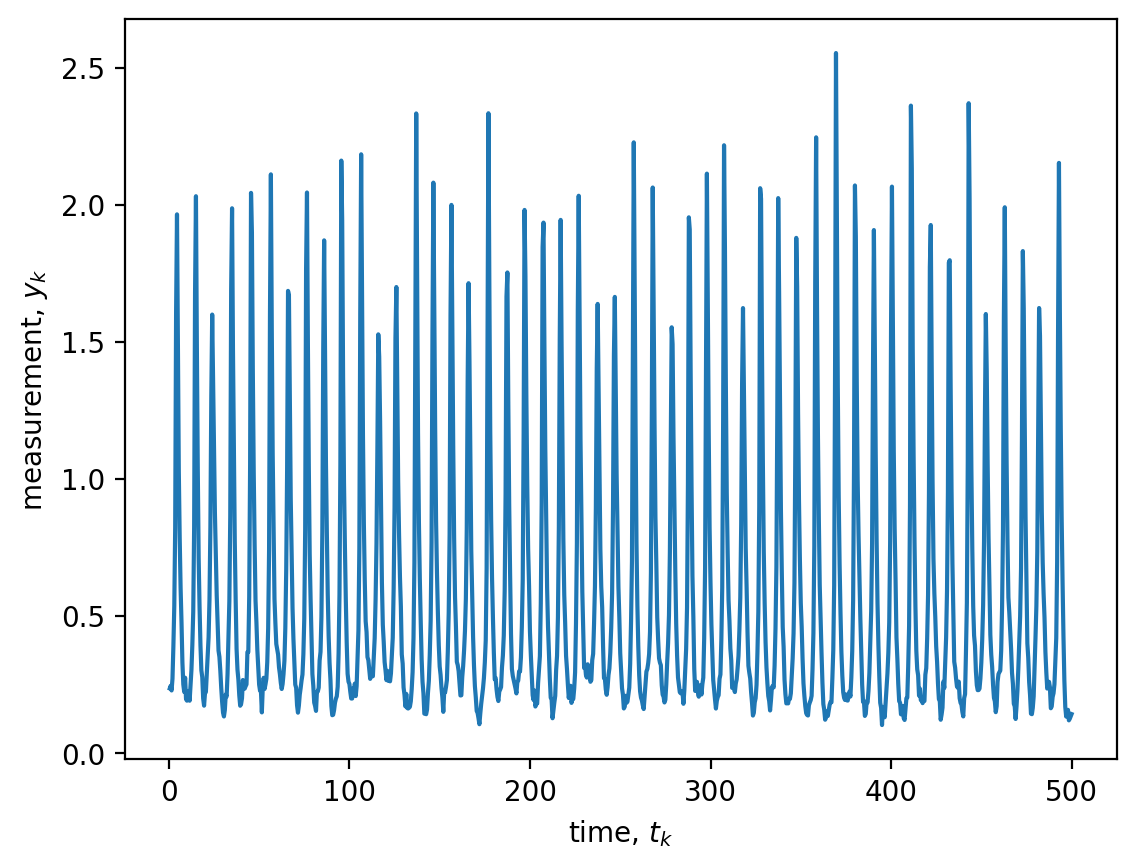

In [3]:
tk = sim['tk']
yk = sim['yk']
yk_clean = sim['yk_clean']
omega0 = sim['omega0']
T0 = sim['T0']

print(f'omega_0 = {omega0:0.5}')

plt.plot(tk, yk)
plt.xlabel('time, $t_k$')
plt.ylabel('measurement, $y_k$');

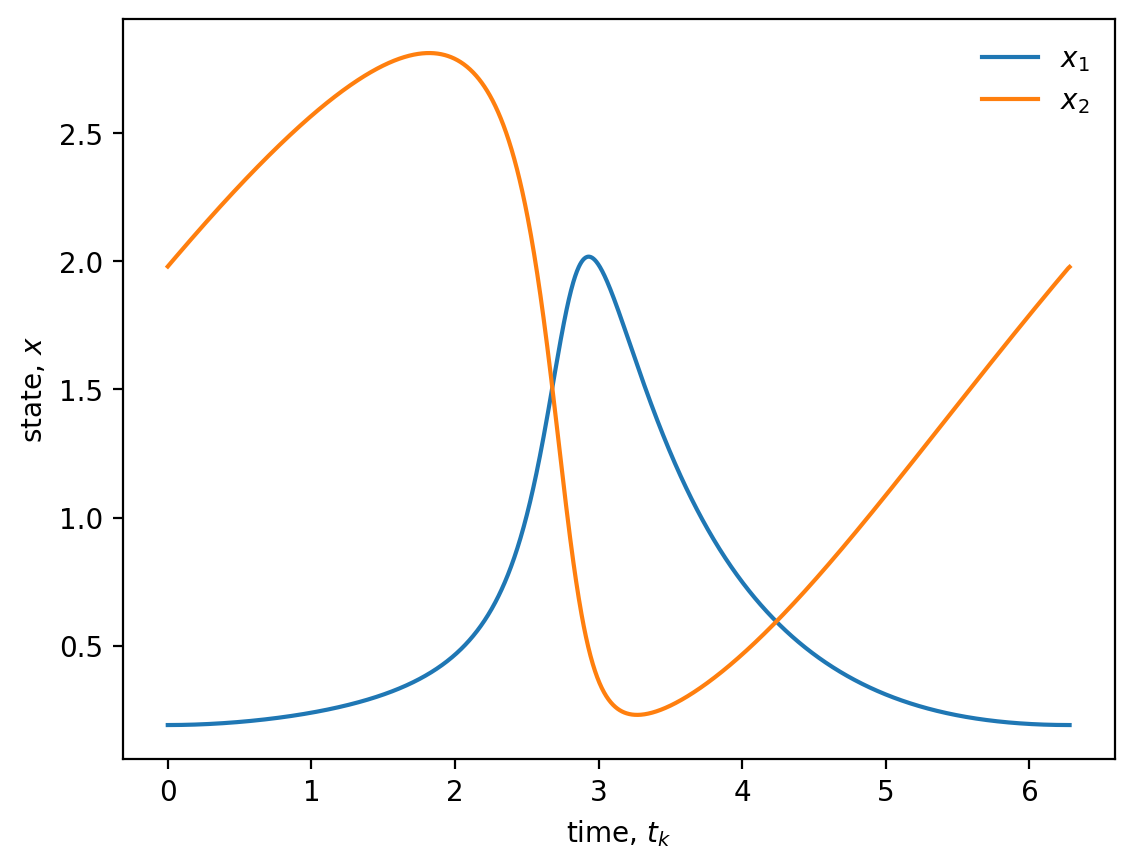

In [4]:
plt.plot(sim['phase_grid'], sim['x_cycle'][:,0], label=r'$x_1$')
plt.plot(sim['phase_grid'], sim['x_cycle'][:,1], label=r'$x_2$')
plt.legend(frameon=False)
plt.xlabel('time, $t_k$')
plt.ylabel('state, $x$');

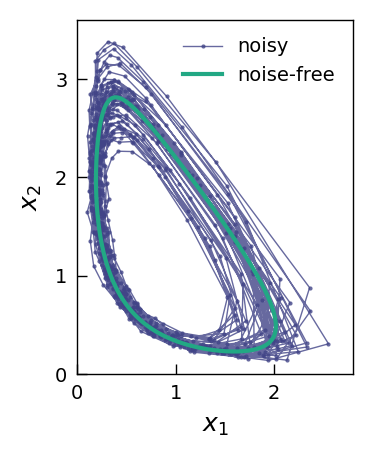

In [5]:
xmax = 2.8
ymax = 3.6

# Desired axes dimensions in centimeters
axes_height_cm = 4.5
axes_width_cm = axes_height_cm * xmax/ymax

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(sim['xk'][:,0], sim['xk'][:,1], '.-', color=cmap(0.2), ms=3, mew=0, alpha=0.8, lw=0.5, label='noisy')
ax.plot(sim['x_cycle'][:,0],sim['x_cycle'][:,1], '-', color=cmap(0.6), lw=1.5, label='noise-free')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'$x_1$', fontsize=9)
ax.set_ylabel(r'$x_2$', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=True, edgecolor='none', fontsize=7)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')
ax.set_yticks([0, 1, 2, 3])

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorOrbit.pdf')

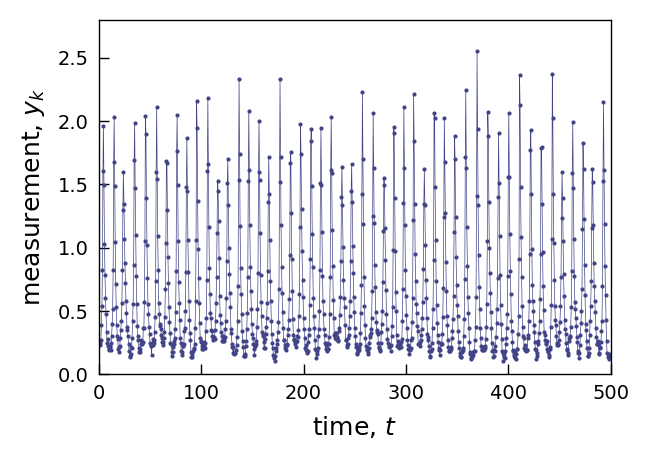

In [6]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, yk, '.-', lw=0.25, mew=0, ms=3, color=cmap(0.2), label='$y_1$')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$', fontsize=9)
ax.set_ylabel(r'measurement, $y_k$', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')
# ax.set_yticks([0, 1, 2, 3])

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, N*dt)
ax.set_ylim(0, xmax)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorTrace.pdf')

In [7]:
list_of_tuples = list(zip(tk,yk))
df = pd.DataFrame(list_of_tuples,
                  columns=['t', 'y'])
df

,t,y
0,0.5,0.235436
1,1.0,0.245073
2,1.5,0.228020
3,2.0,0.270490
4,2.5,0.389099
...,...,...
995,498.0,0.157255
996,498.5,0.118932
997,499.0,0.124965
998,499.5,0.133679


In [8]:
df.to_csv('plots/simulated_data_GO.csv',index=False)

## Add Regularizing Noise

In [9]:
R_add = 0.02 # regularizing noise magnitude
data = (tk, yk)

tk, yk_reg = GO.add_regularizing_noise(data,R_add, rng)
data_reg = (tk, yk_reg)

## Estimate frequency

In [10]:
omega_FFT, _ , _ = GO.estimate_frequency_fft(data)
print(f'Frequency estimate = {omega_FFT:.5f}')
print(f'Noise-free frequency = {omega0:.5f}')

Frequency estimate = 0.61889
Noise-free frequency = 0.61836


#  Estimating latent phase, $p(\theta_{1:N} \mid y_{1:N}, \lambda)$

## Estimate initial phase

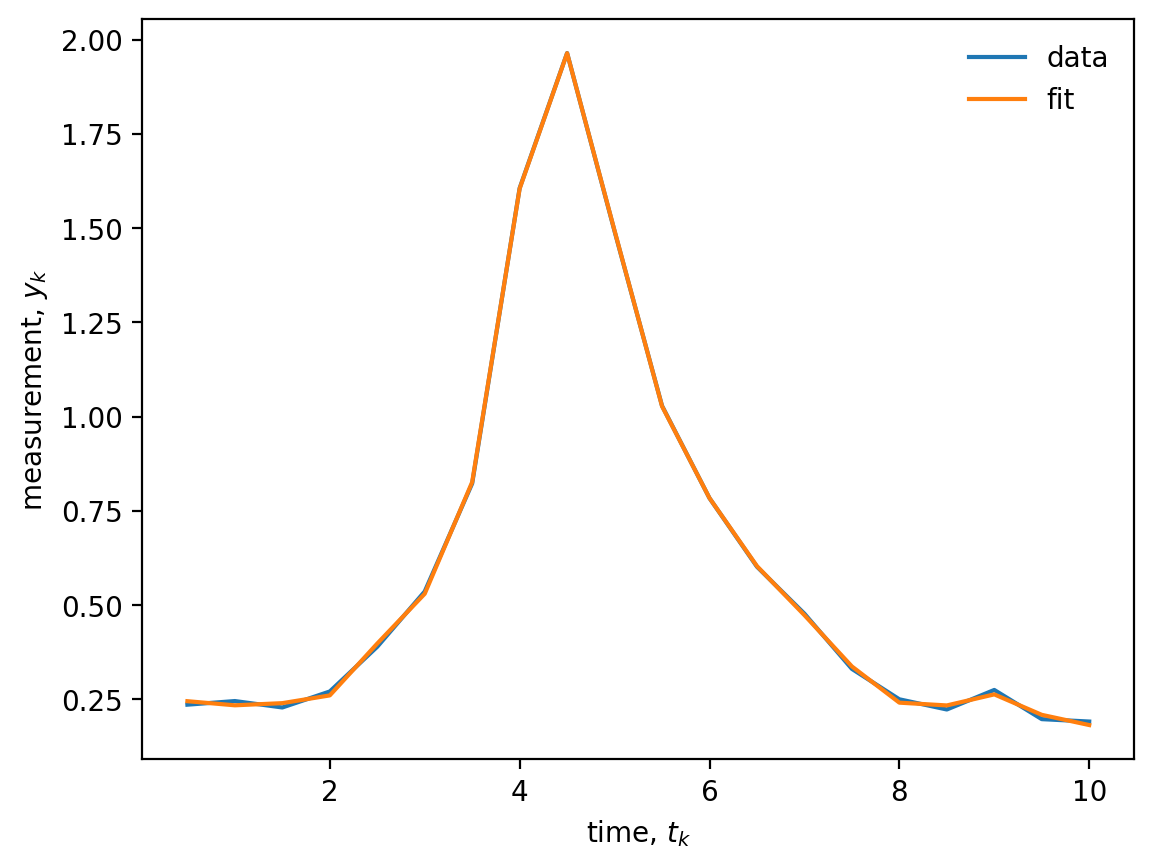

In [11]:
M = 8          # number of Fourier modes
window_size = int(T0/dt)   # select the window used for initialization
phase_init = GO.estimate_initial_phase_regression(data, omega_FFT, window_size, R_add, M=M)

plt.plot(tk[0:window_size], yk[0:window_size], label='data')
plt.plot(tk[0:window_size], phase_init['y_fit'], label='fit')
plt.legend(frameon=False)
plt.xlabel('time, $t_k$')
plt.ylabel('measurement, $y_k$');

In [12]:
mu_theta = phase_init["phi_mean"] + omega_FFT * tk[0]
sigma_theta = 2 * phase_init["phi_std"] # inflate by 2 to be cautious
state_priors = (mu_theta, sigma_theta)

## Priors $p(\lambda)$

In [13]:
# initial guesses 
Dtheta = 0.00648471  # phase reduction prediciton

# parameter priors 
mu_omega = omega_FFT
sigma_omega = 0.1*omega_FFT
alpha_D = 2.0               # Laplace variance 1/alpha
beta_D = alpha_D*Dtheta     # mode = alpha/beta for log parameterization
alpha_R = 2.0               # Laplace variance 1/alpha
beta_R = alpha_R*R_add      # mode = alpha/beta for log parameterization
mu_A = 0.0
sigma_A = 2.0
sigma_q = 2.0

param_priors = (mu_omega, sigma_omega, 
                alpha_D, beta_D, 
                alpha_R, beta_R, 
                mu_A, sigma_A,
                sigma_q)

priors = state_priors + param_priors

## Global Phase Filter

In [15]:
A = phase_init['A']
B = phase_init['B']
param = (omega_FFT, np.log(Dtheta), np.log(R_add), A, B)
# param = lambda_map
n_theta = 256

phase_filter = GO.global_phase_filter(
    param,
    data_reg,
    state_priors,
    n_theta=n_theta,
    validate=True,
)

phase_smoother = GO.global_phase_smoother(
    phase_filter,
    validate=True,
)

theta_grid = phase_smoother["theta_grid"]
gamma = phase_smoother["gamma"]   # shape (N, n_theta)

We can compute $\log p(y_{1:N}\mid \lambda)$ from the Kalman filter.

In [16]:
nlml = GO.neg_log_marginal_likelihood(param, data_reg, state_priors, n_theta=n_theta)
print(f'Negative log marginal likelihood: {nlml:.5}')

Negative log marginal likelihood: -214.58


### Inferred phase

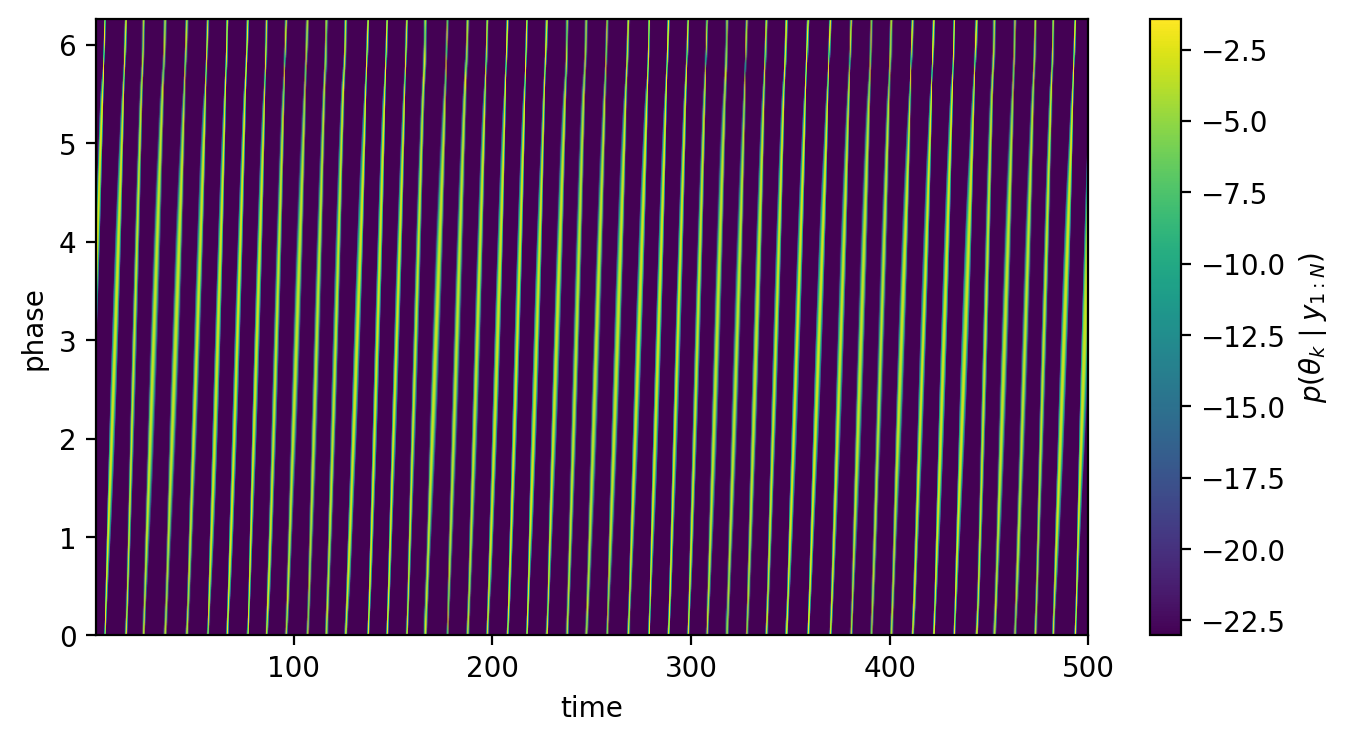

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))

im = ax.imshow(
    np.log(gamma.T+1e-10),
    # gamma.T,
    origin="lower",
    aspect="auto",
    extent=[tk[0], tk[-1], theta_grid[0], theta_grid[-1]],
)

ax.set_xlabel("time")
ax.set_ylabel("phase")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$p(\theta_k \mid y_{1:N})$")

Mean and variance of the phase.

In [18]:
# gamma shape: (N, n_theta)
# theta_grid shape: (n_theta,)
z = gamma @ np.exp(1j * theta_grid)   # E[e^{i theta_k} | y]

theta_mean_wrapped = np.angle(z)      # in [-pi, pi)
theta_mean = np.unwrap(theta_mean_wrapped)

Rbar = np.abs(z)                      # mean resultant length

# Circular standard deviation
theta_std = np.sqrt(-2.0 * np.log(np.clip(Rbar, 1e-15, 1.0)))

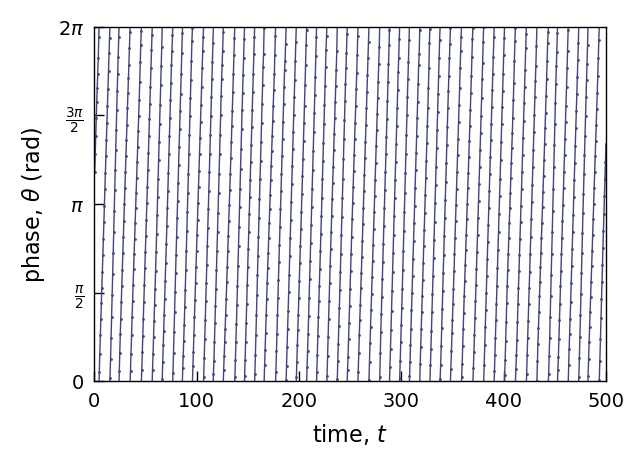

In [19]:
scale = 1

# Desired axes dimensions in centimeters
axes_width_cm = 6.5 * scale
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm * cm    # ~2.362 in
axes_height_in = axes_height_cm * cm  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, np.mod(theta_mean, 2*np.pi), '.', ms=2, mew=0, color=cmap(0.2))
ax.plot(tk, theta_mean + 2*np.pi, '-', lw=0.5, label=r'inferred, $\hat{\theta}_{k|N}$', color=cmap(0.2))

theta_upper = theta_mean + theta_std
theta_lower = theta_mean - theta_std
ax.fill_between(tk, theta_upper + 2*np.pi, theta_lower + 2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);

for i in range(0,50):
    ax.plot(tk, theta_mean - i*2*np.pi, '-', lw=0.5, color=cmap(0.2))
    ax.fill_between(tk, theta_upper - i*2*np.pi, theta_lower - i*2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);

# Set axis labels with font size 8 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'phase, $\theta$ (rad)', fontsize=8)

# Create legend (frame turned off)
# ax.legend(frameon=True, fontsize=8, edgecolor='none', loc=1)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([0,
               np.pi/2,
               np.pi,
               3*np.pi/2,
               2*np.pi])

ax.set_yticklabels([r'$0$',
                    r'$\frac{\pi}{2}$',
                    r'$\pi$',
                    r'$\frac{3\pi}{2}$',
                    r'$2\pi$'])

ax.set_xlim(0, scale*N*dt)
ax.set_ylim(0, 2*np.pi)
# ax.set_xlim(150,300)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorTrace_Inferred.pdf')

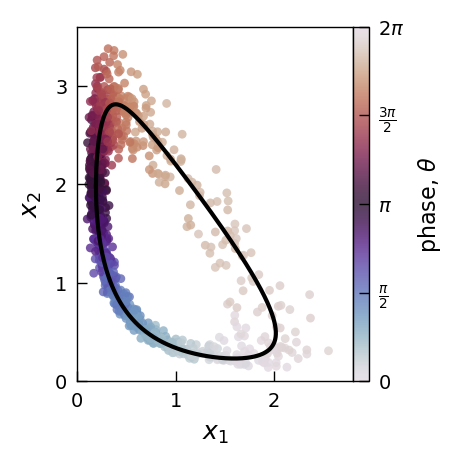

In [45]:
xmax = 2.8
ymax = 3.6

# fixed axis geometry
ax_h = 4.5 * cm
ax_w = ax_h * xmax / ymax
gap = 0.0 * cm
cbar_w = 0.2 * cm

left = 1.5 * cm
bottom = 1.0 * cm
right = 1.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + gap + cbar_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

cax = fig.add_axes([
    (left + ax_w + gap) / fig_w,
    bottom / fig_h,
    cbar_w / fig_w,
    ax_h / fig_h
])

# Plot the data
cf = ax.scatter(sim['xk'][:,0], sim['xk'][:,1], c=np.mod(theta_mean, 2*np.pi), s=10, alpha=0.8,
          cmap=cmap2, lw=0)
# ax.plot(sim['xk'][:,0], sim['xk'][:,1], '.-', color=cmap(0.2), ms=3, mew=0, alpha=0.8, lw=0.5, label='noisy')
ax.plot(sim['x_cycle'][:,0],sim['x_cycle'][:,1], 'k-', lw=1.5, label='noise-free')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'$x_1$', fontsize=9)
ax.set_ylabel(r'$x_2$', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')
ax.set_yticks([0, 1, 2, 3])

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

cb = fig.colorbar(cf, cax=cax)
cb.set_label(r'phase, $\theta$', fontsize=8)
cb.ax.tick_params(axis='both', which='both', direction='in', width=0.5, labelsize=7)
cax.set_yticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
cax.set_yticklabels([
    r"$0$",
    r"$\frac{\pi}{2}$",
    r"$\pi$",
    r"$\frac{3\pi}{2}$",
    r"$2\pi$"
])
for spine in cax.spines.values():
    spine.set_linewidth(0.5)
    
plt.savefig('plots/GlycolyticOscillatorOrbit_Phase.pdf')

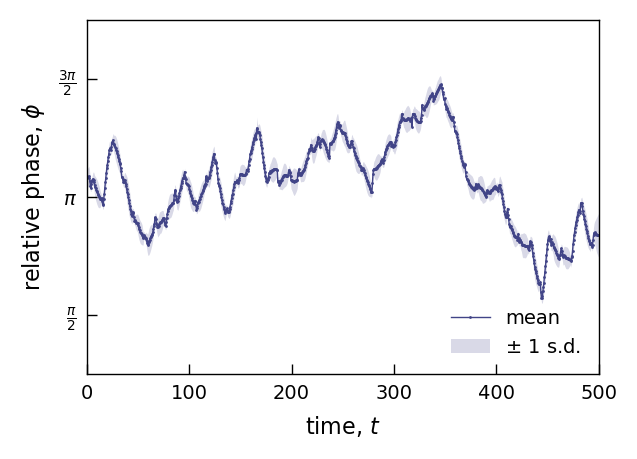

In [21]:
# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

ax.plot(tk, theta_mean - param[0]*tk + 2*np.pi, '.-', ms=2, mew=0, lw=0.5, 
        color=cmap(0.2), label=r'mean');

phi_upper = theta_mean - param[0]*tk + 2*np.pi + theta_std
phi_lower = theta_mean - param[0]*tk + 2*np.pi - theta_std
ax.fill_between(tk, phi_upper, phi_lower, color=cmap(0.2), alpha=0.2, lw=0,
               label=r'$\pm$ 1 s.d.');

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'relative phase, $\phi$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([np.pi/2,
               # 3*np.pi/4,
               np.pi,
               # 5*np.pi/4,
               3*np.pi/2])

ax.set_yticklabels([r'$\frac{\pi}{2}$',
                    # r'$\frac{3\pi}{4}$',
                    r'$\pi$',
                    # r'$\frac{5\pi}{4}$',
                    r'$\frac{3\pi}{2}$'])

ax.set_xlim(0, N*dt)
ax.set_ylim(1*np.pi/4, 7*np.pi/4)
plt.legend(frameon=False, fontsize=7, loc=4)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorTrace_Phi.pdf')

### Posterior predictive distribution

In [22]:
R = np.exp(param[2])

# waveform on phase grid
q_grid = phase_filter["q_grid"]   # or q_fourier(theta_grid, A, B)

# posterior predictive mean
y_mean = gamma @ q_grid

# posterior predictive variance:
# Var(y_rep | data) = R + Var[q(theta_k) | data]
q2_mean = gamma @ (q_grid**2)
y_var = R + q2_mean - y_mean**2
y_std = np.sqrt(np.maximum(y_var, 0.0))

# 95% Gaussian moment-matched band
lo = y_mean - 1.96 * y_std
hi = y_mean + 1.96 * y_std

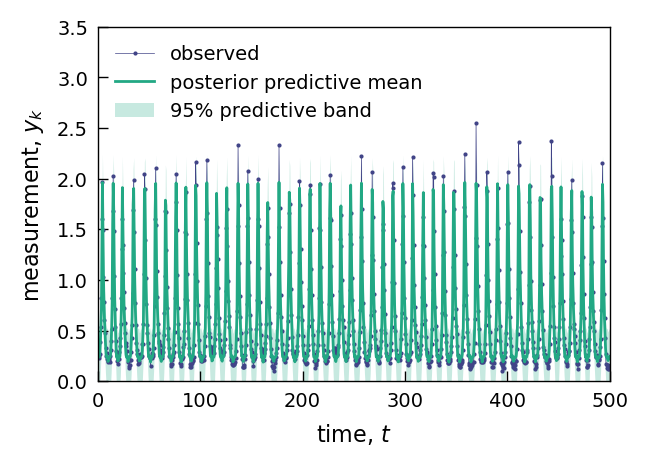

In [23]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, yk, '.-', lw=0.25, mew=0, ms=3, color=cmap(0.2), label='observed')
ax.plot(tk, y_mean, color=cmap(0.6), lw=1, label="posterior predictive mean")
ax.fill_between(tk, lo, hi, color=cmap(0.6), lw=0, alpha=0.25, label="95% predictive band")

# Set axis labels with font size 8 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'measurement, $y_k$', fontsize=8)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=7)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, N*dt)
ax.set_ylim(0, 3.5)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillator_PosteriorPredictive.pdf')

### Residuals

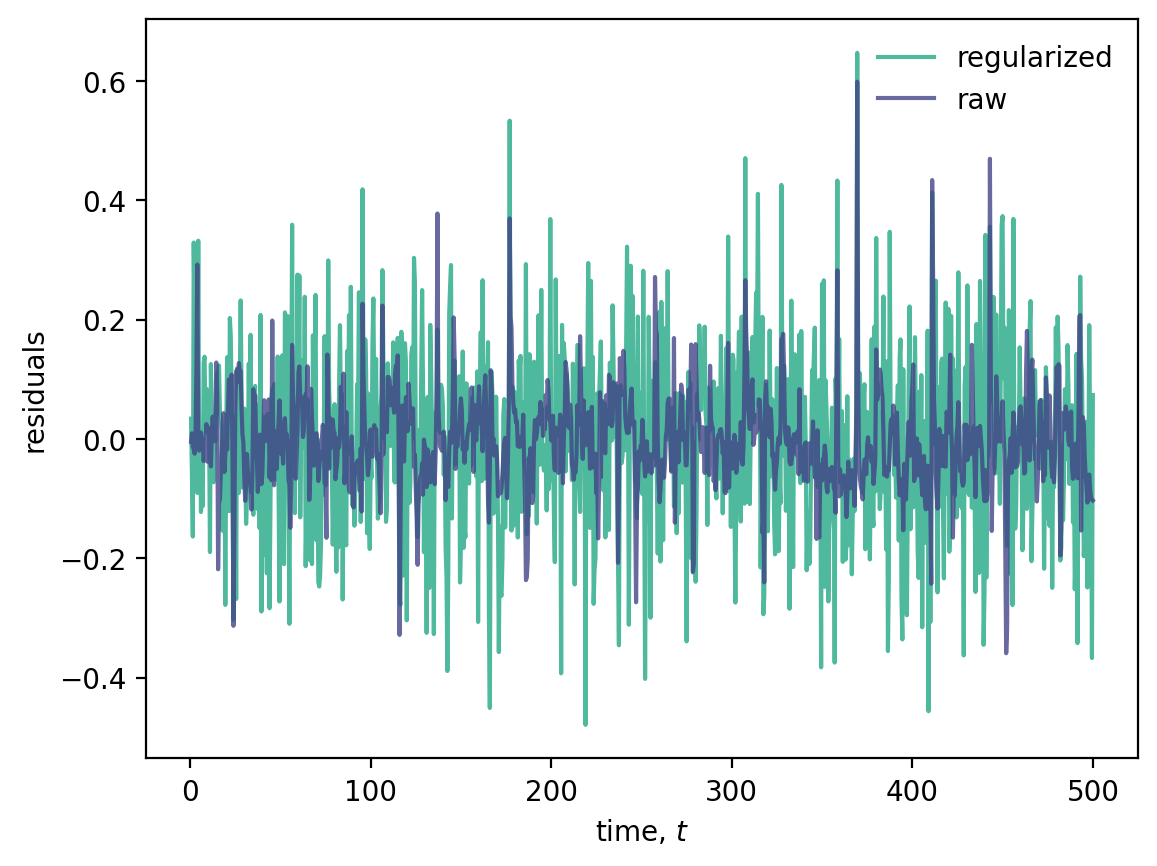

In [24]:
res = yk - y_mean
res_reg = yk_reg - y_mean

plt.plot(tk, res_reg, color=cmap(0.6), alpha=0.8, label='regularized')
plt.plot(tk, res, color=cmap(0.2), alpha=0.8, label='raw')

plt.legend(frameon=False)
plt.xlabel('time, $t$');
plt.ylabel('residuals');

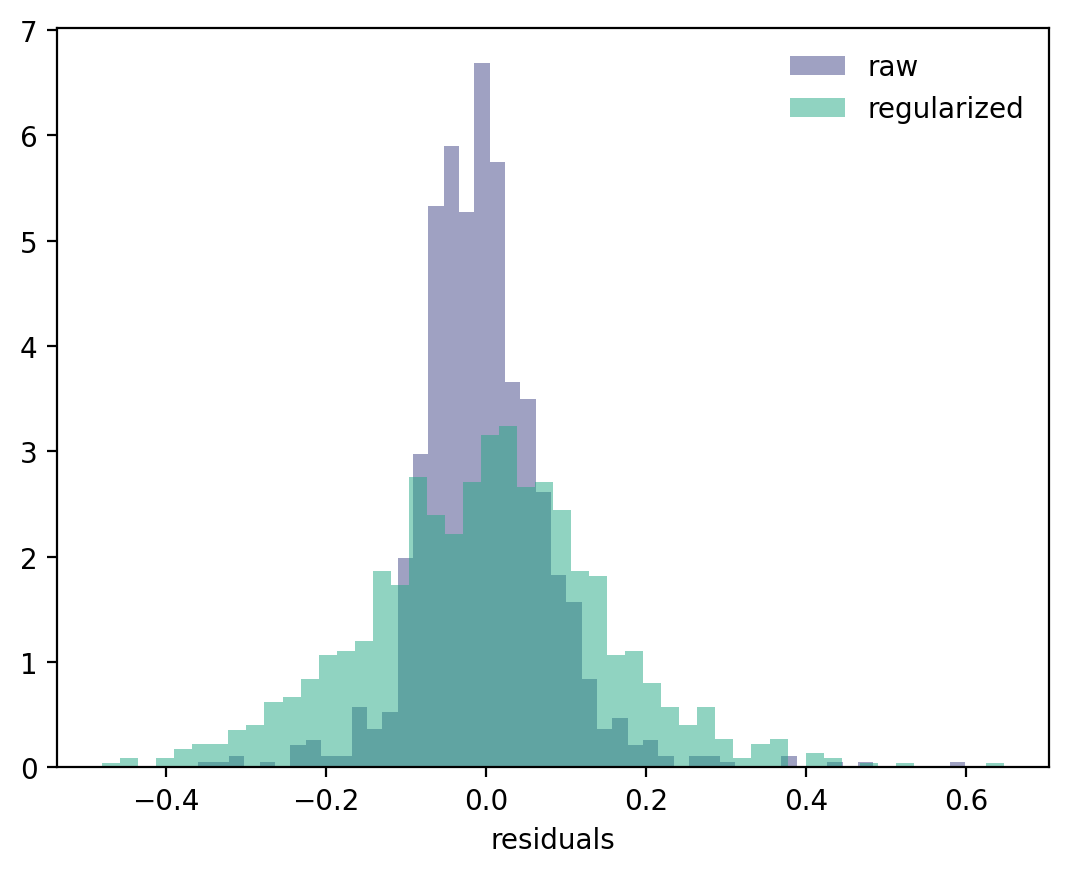

In [25]:
plt.hist(res, bins=50, color=cmap(0.2), alpha=0.5, label='raw', density=True)
plt.hist(res_reg, bins=50, color=cmap(0.6), alpha=0.5, label='regularized', density=True)
plt.legend(frameon=False)
plt.xlabel('residuals');

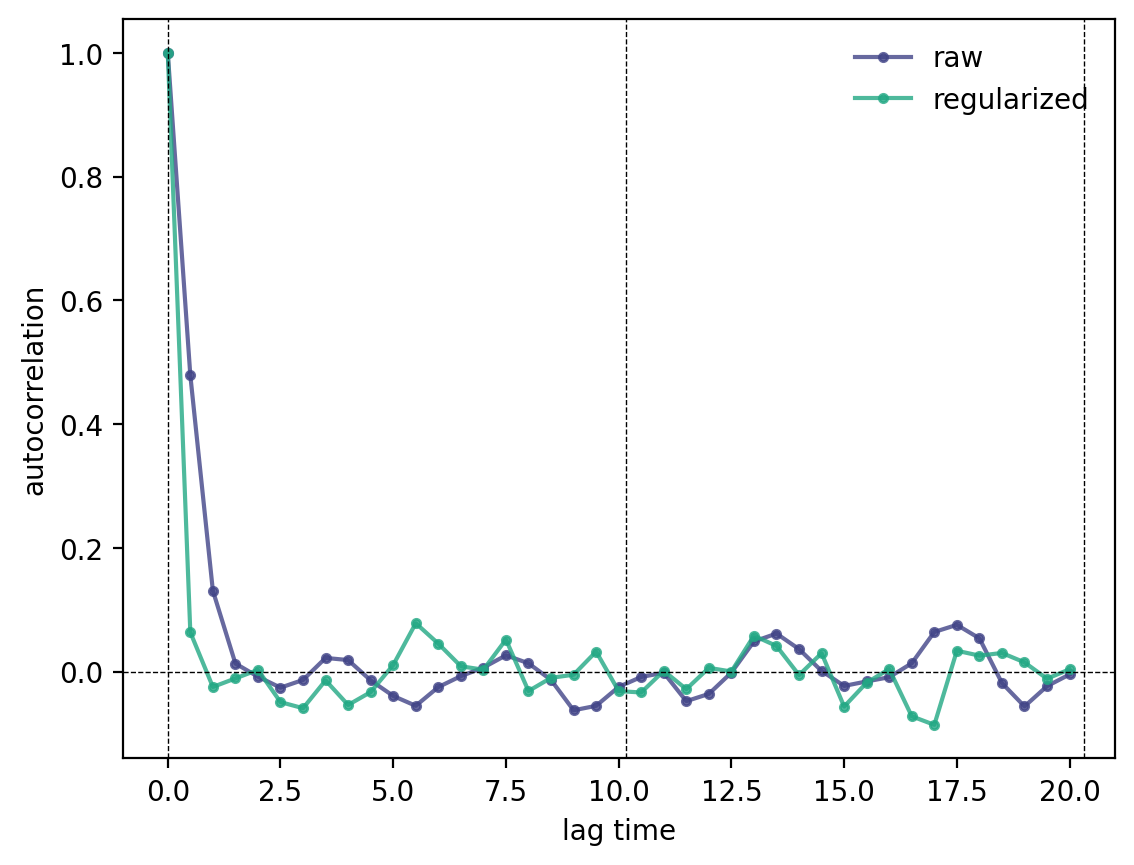

In [26]:
acf = np.correlate(res, res, mode="full")[len(res)-1:]
acf = acf / acf[0]
lags = np.arange(len(acf)) * dt

acf_reg = np.correlate(res_reg, res_reg, mode="full")[len(res_reg)-1:]
acf_reg = acf_reg / acf_reg[0]

cycles = 2
imax = int(np.ceil(cycles*T0/dt))
plt.plot(lags[:imax], acf[:imax], '.-', color=cmap(0.2), alpha=0.8, label='raw')
plt.plot(lags[:imax], acf_reg[:imax], '.-', color=cmap(0.6), alpha=0.8, label='regularized')

for i in range(cycles+1):
    plt.axvline(i*T0, color='k', lw=0.5, ls='--')
plt.axhline(0, color='k', lw=0.5, ls='--')

plt.legend(frameon=False, loc=1)
plt.ylabel('autocorrelation')
plt.xlabel('lag time');

## Mean Squared Displacement
### $p(\mathrm{MSD}\mid y_{1:N},\lambda)$

In [27]:
omega, lnDtheta, lnR, A, B = param
Dtheta = np.exp(lnDtheta)
dt = tk[1] - tk[0]

lags = np.arange(1, int(N/4))
tau = lags * dt

# sample phase trajectories conditioned on measurements
theta_samps, idx_samps = GO.sample_phase_trajectories_global(
    phase_filter,
    n_samples=200,
    rng=np.random.default_rng(1),
)

# compute the MSD from the sampled phase trajectories
msd = GO.phase_msd_from_samples(
    theta_samps,
    lags,
    omega=omega,
    dt=dt,
    subtract_drift=True,
)

# compute the MSD for each sampled phase trajectory
msd_samples = np.empty((theta_samps.shape[0], len(lags)))
for s in range(theta_samps.shape[0]):
    msd_samples[s] = GO.phase_msd_from_samples(
        theta_samps[s:s+1],
        lags,
        omega=omega,
        dt=dt,
        subtract_drift=True,
    )

msd_med = np.percentile(msd_samples, 50, axis=0)
msd_lo = np.percentile(msd_samples, 2.5, axis=0)
msd_hi = np.percentile(msd_samples, 97.5, axis=0)

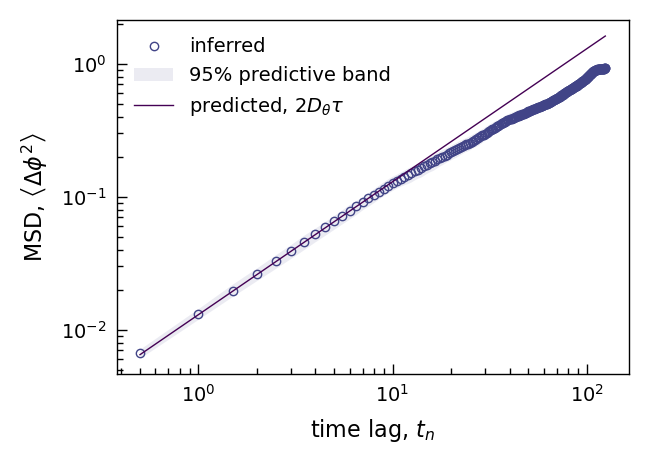

In [28]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.loglog(tau, msd_med, 'o', mew=0.5, ms=3, mec=cmap(0.2), mfc='None', alpha=1, 
           label=r'inferred')
plt.fill_between(tau, msd_lo, msd_hi,  lw=0, color=cmap(0.2), alpha=0.1,
                label="95% predictive band")

# Theory
ax.plot(tau, 2*Dtheta*tau, '-', lw=0.5, color=cmap(0), label=r'predicted, $2D_\theta \tau$')

# Set axis labels with font size 8 pt
ax.set_xlabel(r'time lag, $t_n$', fontsize=8)
ax.set_ylabel(r"MSD, $\left\langle \Delta\phi^2 \right\rangle$",  fontsize=8)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=7, loc=0)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorMSD.pdf')

### $p(\mathrm{MSD}\mid \lambda)$

It is helpful to compute the uncertainty we might expect from many simulated trajectories.

In [29]:
def simulate_phase_trajectory(omega, Dtheta, N, dt, rng, theta0=0.0):
    dtheta = omega * dt + np.sqrt(2 * Dtheta * dt) * rng.standard_normal(N - 1)
    theta = np.empty(N)
    theta[0] = theta0
    theta[1:] = theta0 + np.cumsum(dtheta)
    return theta

def drift_subtracted_msd(theta, lags, omega, dt):
    msd = np.empty(len(lags))
    for a, lag in enumerate(lags):
        tau = lag * dt
        dtheta = theta[lag:] - theta[:-lag] - omega * tau
        msd[a] = np.mean(dtheta**2)
    return msd

In [30]:
rng = np.random.default_rng(1)
samples = 2000

msd_samples = np.empty((samples, len(lags)))

for s in range(samples):
    theta_s = simulate_phase_trajectory(
        omega, Dtheta, len(tk), dt, rng
    )
    msd_samples[s] = drift_subtracted_msd(theta_s, lags, omega, dt)

msd_pred = 2 * Dtheta * tau
msd_lo, msd_hi = np.percentile(msd_samples, [2.5, 97.5], axis=0)

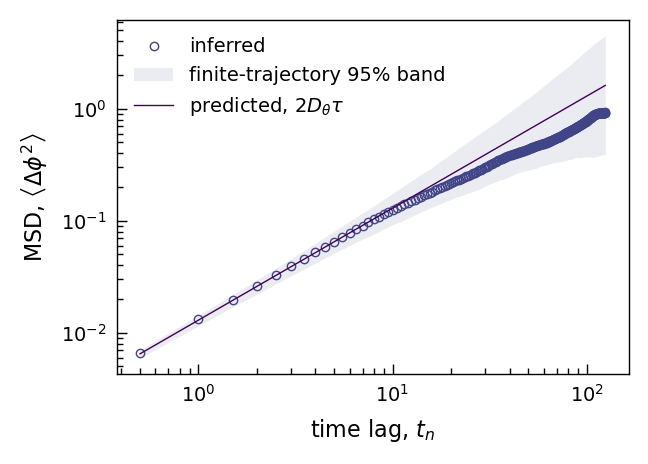

In [31]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.loglog(tau, msd, 'o', mew=0.5, ms=3, mec=cmap(0.2), mfc='None', alpha=1, 
           label=r'inferred')
# plt.fill_between(tau, msd_lo, msd_hi,  lw=0, color=cmap(0.2), alpha=0.1,
#                 label="95% predictive band")
plt.fill_between(tau, msd_lo, msd_hi, lw=0, color=cmap(0.2), alpha=0.1, label="finite-trajectory 95% band")

# Theory
ax.plot(tau, 2*Dtheta*tau, '-', lw=0.5, color=cmap(0), label=r'predicted, $2D_\theta \tau$')

# ax.plot(tau, 2*0.00648471*tau, '--', lw=0.5, color=cmap(0))
# ax.axhline(y=0.1985**2)
# ax.axvline(x=1/0.329154)
# ax.axvline(x=1/omega0)

# Set axis labels with font size 8 pt
ax.set_xlabel(r'time lag, $t_n$', fontsize=8)
ax.set_ylabel(r"MSD, $\left\langle \Delta\phi^2 \right\rangle$",  fontsize=8)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=7, loc=0)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GlycolyticOscillatorMSD_v2.pdf')

# Estimating parameters, $p(\lambda \mid y_{1:N})$

## Optimization of $\log p(\lambda \mid y)$ 

### Gradient-free optimizer

We can optimize $-\log p(\lambda\mid y)$ directly using a gradient free optimizer like Powell or Nelder-Mead.

In [32]:
def objective(x):
    try:
        val = GO.neg_log_posterior(
            GO.unpack_param(x, M),
            data_reg,
            priors,
            n_theta=256,
        )

        if not np.isfinite(val):
            return BAD

        return val

    except (FloatingPointError, RuntimeError, ValueError, OverflowError):
        return BAD

iter_count = {"k": 0}

def callback(xk):
    iter_count["k"] += 1

    omega, lnDtheta, lnR, A, B = GO.unpack_param(xk, M)

    print(
        f"{iter_count['k']:4d}  "
        f"omega={omega:.6f}  "
        f"lnDtheta={lnDtheta:.6f}  "
        f"lnR={lnR:.6f}"
    )


In [33]:
%%time

param0 = GO.pack_param(
    omega_FFT,
    np.log(Dtheta),
    np.log(R),
    phase_init["A"],
    phase_init["B"],
)

res = minimize(
    fun=objective,
    x0=param0,
    method="Powell",
    callback=callback,
)

print(res, "\n")

   1  omega=0.617348  lnDtheta=-4.742468  lnR=-3.645368
   2  omega=0.617398  lnDtheta=-5.057546  lnR=-3.671420
   3  omega=0.617445  lnDtheta=-5.045209  lnR=-3.670488
   4  omega=0.617447  lnDtheta=-5.042856  lnR=-3.671041
 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: -263.788292970469
       x: [ 6.174e-01 -5.043e+00 ... -3.732e-02 -2.907e-02]
     nit: 4
   direc: [[ 1.000e+00  0.000e+00 ...  0.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00 ...  0.000e+00  0.000e+00]
           ...
           [ 0.000e+00  0.000e+00 ...  1.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00 ...  0.000e+00  1.000e+00]]
    nfev: 762 

CPU times: user 22.7 s, sys: 425 ms, total: 23.1 s
Wall time: 23.6 s


In [34]:
lambda_map = GO.unpack_param(res.x, M)
lambda_map

(np.float64(0.6174465690930733),
 np.float64(-5.042856415982289),
 np.float64(-3.6710409618272126),
 array([ 0.60479915,  0.62493202,  0.31355242,  0.17477923,  0.09582703,
         0.03074233,  0.01640258, -0.00928905, -0.01343019]),
 array([ 0.        ,  0.        , -0.0360052 , -0.07455602, -0.08248045,
        -0.0535752 , -0.05026624, -0.03731761, -0.02907245]))

### Noise condition

If `R_eff / threshold` is greater than or of order 1, then the tolerance is large enough not to force the filter to resolve observation changes smaller than a typical one-step diffusive phase displacement.

Dtheta_MAP           = 6.45528e-03
R_eff                = 2.54500e-02
<|q'(theta)|^2>      = 8.51926e-01
Dtheta <q'^2> / mu   = 1.67077e-02
R_eff / threshold    = 1.523
sqrt ratio           = 1.234


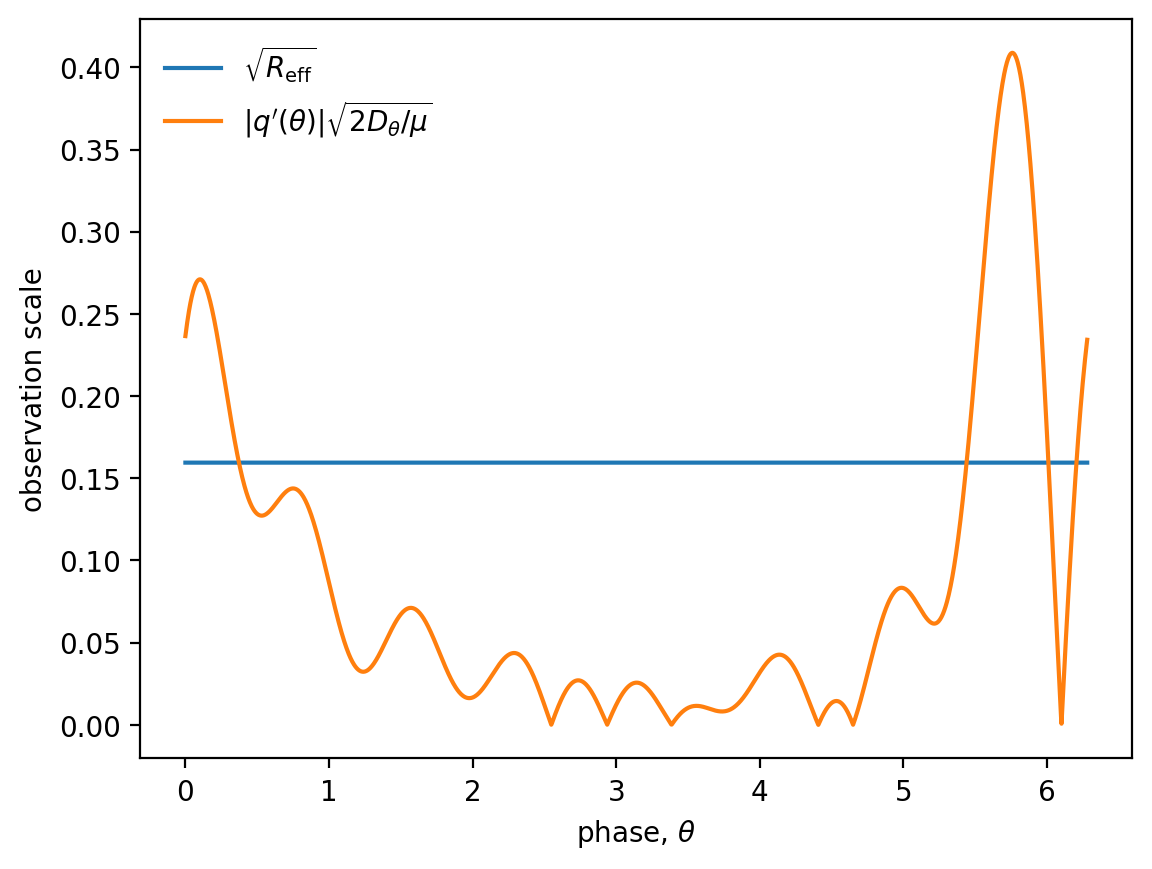

In [35]:
A = lambda_map[3]
B = lambda_map[4]

omega_map = lambda_map[0]
Dtheta_map = np.exp(lambda_map[1])
R_eff = np.exp(lambda_map[2])

theta_grid = np.linspace(0, 2*np.pi, 2000, endpoint=False)

q = GO.q_fourier(theta_grid, A, B)
dq = GO.q_fourier_prime(theta_grid, A, B)

dq2_mean = np.mean(dq**2)

mu = 0.329154  # relaxation rate
R_phase_step = Dtheta_map * dq2_mean / mu

print(f"Dtheta_MAP           = {Dtheta_map:.5e}")
print(f"R_eff                = {R_eff:.5e}")
print(f"<|q'(theta)|^2>      = {dq2_mean:.5e}")
print(f"Dtheta <q'^2> / mu   = {R_phase_step:.5e}")
print(f"R_eff / threshold    = {R_eff / R_phase_step:.3f}")
print(f"sqrt ratio           = {np.sqrt(R_eff / R_phase_step):.3f}")

plt.plot(theta_grid, np.sqrt(R_eff) * np.ones_like(theta_grid),
         label=r"$\sqrt{R_\mathrm{eff}}$")

plt.plot(theta_grid, np.sqrt(Dtheta_map / mu) * np.abs(dq),
         label=r"$|q'(\theta)|\sqrt{2D_\theta / \mu}$")

plt.xlabel(r"phase, $\theta$")
plt.ylabel("observation scale")
plt.legend(frameon=False);

### Waveform

In [36]:
theta = sim["phase_grid"]
q = sim["x_cycle"][:, 0]

# Fourier coefficients of x1 in the current phase convention
A1 = 2.0 * np.mean(q * np.cos(theta))
B1 = 2.0 * np.mean(q * np.sin(theta))

# Shift so that B1 -> 0 for q(theta) = q_shifted(theta + phi)
phi = np.arctan2(-B1, A1)

print(f"A1 = {A1:.6f}")
print(f"B1 = {B1:.6f}")
print(f"phase shift phi = {phi:.6f} rad")
print(f"phase shift phi/pi = {phi/np.pi:.6f}")

# Check by refitting coefficients in the shifted coordinate
theta_shifted = theta + phi

A1_shifted = 2.0 * np.mean(q * np.cos(theta_shifted))
B1_shifted = 2.0 * np.mean(q * np.sin(theta_shifted))

print(f"A1 shifted = {A1_shifted:.6f}")
print(f"B1 shifted = {B1_shifted:.6e}")

A1 = -0.615326
B1 = -0.004080
phase shift phi = 3.134962 rad
phase shift phi/pi = 0.997889
A1 shifted = 0.615340
B1 shifted = -1.705303e-16


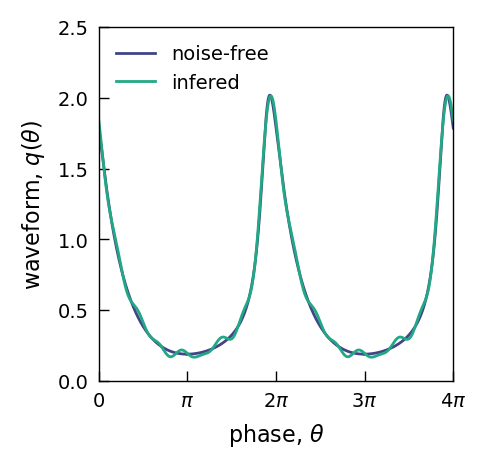

In [37]:
theta_fit = np.linspace(0,4*np.pi, 500)
y_fit = GO.q_fourier(theta_fit, A, B)

# fixed axis geometry
ax_h = 4.5 * cm
ax_w = 4.5 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + gap + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

# Plot the data
ax.plot(sim['phase_grid']+phi, sim['x_cycle'][:,0], 
        color=cmap(0.2), lw=1, label=r'noise-free')
ax.plot(sim['phase_grid']+phi-2*np.pi, sim['x_cycle'][:,0], 
        color=cmap(0.2), lw=1)
ax.plot(sim['phase_grid']+phi+2*np.pi, sim['x_cycle'][:,0],
        color=cmap(0.2), lw=1)
ax.plot(theta_fit, y_fit, lw=1, color=cmap(0.6), label='infered')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'phase, $\theta$', fontsize=8)
ax.set_ylabel(r'waveform, $q(\theta)$', fontsize=8);

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_xticks([0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi])
ax.set_xticklabels([
    r"$0$",
    r"$\pi$",
    r"$2\pi$",
    r"$3\pi$",
    r"$4\pi$",
])

ax.legend(frameon=False, fontsize=7, loc=2)

# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, 4*np.pi)
ax.set_ylim(0, 2.5)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    
plt.savefig('plots/GlycolyticOscillator_Waveform.pdf')

### Finite difference hessian

In [38]:
%%time

omega_map, lnDtheta_map, lnR_map, A_map, B_map = lambda_map

# Hessian only in x = [omega, lnDtheta, lnR], holding  A, B fixed
def f_dyn(x):
    omega, lnDtheta, lnR = x
    param = (omega, lnDtheta, lnR, A_map, B_map)
    return GO.neg_log_posterior(param, data, priors)

x_dyn = np.array([omega_map, lnDtheta_map, lnR_map])

hessFunc = nd.Hessian(f_dyn)
H_dyn = hessFunc(x_dyn)

# Symmetrize for numerical stability
H_dyn = 0.5 * (H_dyn + H_dyn.T)

cov_dyn = np.linalg.inv(H_dyn)

omega_se = np.sqrt(cov_dyn[0, 0])
lnDtheta_se = np.sqrt(cov_dyn[1, 1])
lnR_se = np.sqrt(cov_dyn[2, 2])

print(f"omega\t= {omega_map:.5f} +/- {omega_se:.5f}")
print(
    f"Dtheta\t= {np.exp(lnDtheta_map):.5f} "
    f"* exp(+/- {lnDtheta_se:.5f})"
)
print(
    f"R\t= {np.exp(lnR_map):.5f} "
    f"* exp(+/- {lnR_se:.5f})"
)


omega	= 0.61745 +/- 0.00510
Dtheta	= 0.00646 * exp(+/- 0.15220)
R	= 0.02545 * exp(+/- 0.09965)
CPU times: user 7.87 s, sys: 81 ms, total: 7.95 s
Wall time: 7.99 s


### Marginal Distributions

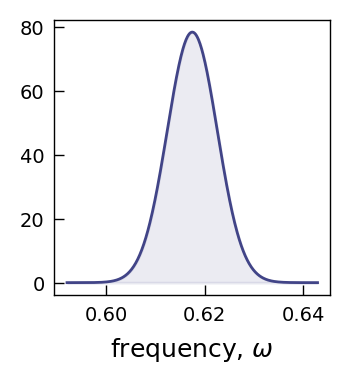

In [39]:
omegas = np.linspace(omega_map-5*omega_se, omega_map+5*omega_se, 500)
pdf = stats.norm.pdf(omegas, loc=omega_map, scale=omega_se)

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(omegas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(omegas,pdf,alpha=0.1,color=cmap(0.2))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'frequency, $\omega$', fontsize=9)

# Create legend (frame turned off)
# ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

# plt.savefig('GO_Frequency.pdf')

1.0000009766457096


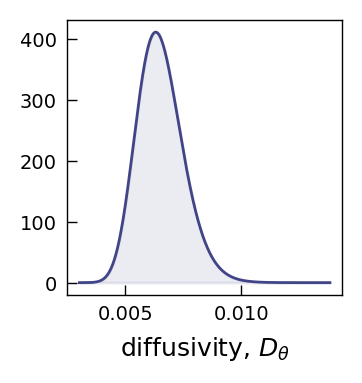

In [40]:
lnDthetas = np.linspace(lnDtheta_map-5*lnDtheta_se, lnDtheta_map+5*lnDtheta_se, 500)
Dthetas = np.exp(lnDthetas)
pdf = stats.lognorm.pdf(Dthetas, s=lnDtheta_se, scale=np.exp(lnDtheta_map))
print(np.trapezoid(pdf, Dthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Dthetas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(Dthetas,pdf,alpha=0.1,color=cmap(0.2))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'diffusivity, $D_\theta$', fontsize=9)
# ax.set_xscale('log')

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

# plt.savefig('GO_Diffusivity.pdf')

1.0000004028445197
0.9999988523990679


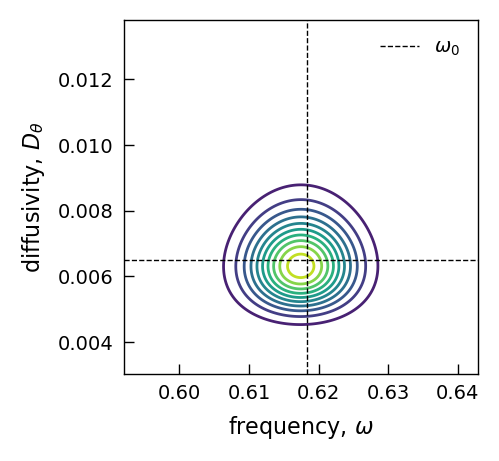

In [41]:
OMEGAS, LNDTHETAS = np.meshgrid(omegas, lnDthetas)

pos = np.dstack((OMEGAS, LNDTHETAS))
DTHETAS = np.exp(LNDTHETAS)

# evaluate pdf
rv = stats.multivariate_normal(np.array([omega_map, lnDtheta_map]), cov_dyn[:2,:2])
Z = rv.pdf(pos)
print(np.trapezoid(np.trapezoid(Z / DTHETAS, omegas), Dthetas))
print(np.trapezoid(np.trapezoid(Z, omegas), lnDthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 4.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# plot
plt.contour(OMEGAS, DTHETAS, Z / DTHETAS, levels=10, linewidths=1)
# plt.plot(omega_map, np.exp(lnDtheta_map), 'kx', ms=3)

Dtheta_PR = 0.00648472
plt.axhline(y=Dtheta_PR, color='k', ls='--', lw=0.5)
plt.axvline(x=omega0, color='k', ls='--', lw=0.5, label=r'$\omega_0$')

# Set axis labels with font size 9 pt
plt.xlabel(r"frequency, $\omega$", fontsize=8)
plt.ylabel(r"diffusivity, $D_\theta$", fontsize=8)

plt.legend(frameon=False, fontsize=7)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/GO_Frequency_Diffusivity.pdf')

## Expectation Maximization (EM) Algorithm


### Iterate to find MAP estimates



In [42]:
%%time

initial_params = lambda_map

lambda_iter = GO.global_phase_em_map_parameters(
    initial_params,
    data_reg,
    priors,
    n_theta=256,
    update_waveform=True,
)

iter	omega		lnDtheta	lnR		|dparam|
1	6.17447e-01	-5.04279e+00	-3.67113e+00	1.024e-02
10	6.17446e-01	-5.04242e+00	-3.67124e+00	2.144e-03
20	6.17446e-01	-5.04235e+00	-3.67124e+00	3.882e-04
30	6.17446e-01	-5.04234e+00	-3.67124e+00	6.960e-05
40	6.17447e-01	-5.04234e+00	-3.67124e+00	1.244e-05
50	6.17447e-01	-5.04234e+00	-3.67124e+00	2.214e-06

Converged at iteration 55 (max relative change = 9.29e-07)
CPU times: user 12.8 s, sys: 813 ms, total: 13.6 s
Wall time: 13.5 s


In [43]:
lambda_map2 = lambda_iter[-1]
lambda_map2

(0.6174465018660751,
 np.float64(-5.042338841026266),
 np.float64(-3.67123781748247),
 array([ 0.60460281,  0.62473957,  0.31375854,  0.17535957,  0.09656776,
         0.0314735 ,  0.01706759, -0.00872703, -0.01287426]),
 array([ 0.        ,  0.        , -0.03501226, -0.07375912, -0.08191792,
        -0.05332836, -0.05010881, -0.03736636, -0.02923504]))

In [44]:
lambda_map

(np.float64(0.6174465690930733),
 np.float64(-5.042856415982289),
 np.float64(-3.6710409618272126),
 array([ 0.60479915,  0.62493202,  0.31355242,  0.17477923,  0.09582703,
         0.03074233,  0.01640258, -0.00928905, -0.01343019]),
 array([ 0.        ,  0.        , -0.0360052 , -0.07455602, -0.08248045,
        -0.0535752 , -0.05026624, -0.03731761, -0.02907245]))